# Bisiklet Kiralama Talebi: Tek Bir Tabloyu Keşfetmek

Her hücre tek bir iş yapar. Yukarıdan aşağıya sırayla çalıştırın.

Bu defterde kullanılan tablo `day.csv`: Washington D.C.'deki Capital Bikeshare sisteminin 2011–2012 yıllarına ait günlük kiralama sayıları ile o günlerin hava durumu ve takvim bilgileri. Her satır bir gün. İş, bir model ya da panel kurulmadan önce tabloyu betimlemek.

Temel soru: **Hava durumu, mevsimsel ve zamansal faktörler bisiklet kiralama talebini nasıl etkiliyor?**

In [4]:
%matplotlib inline
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

In [6]:
# --- Session restore / analysis setup ---

import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

# Veriyi yeniden yükle
df = pd.read_csv("data/day.csv")

# Daha önce gerekçelendirdiğimiz iki hücrelik temizliği yeniden uygula
hum_day = df["dteday"] == "2011-03-10"
atemp_day = df["dteday"] == "2012-08-17"

df.loc[hum_day, "hum"] = pd.NA
df.loc[atemp_day, "atemp"] = pd.NA

# Sık kullandığımız yardımcı değişkenler
numeric = ["cnt", "temp", "atemp", "hum", "windspeed"]
dates = pd.to_datetime(df["dteday"], errors="coerce")

print("Session ready")
print("df shape:", df.shape)
print("missing cells:", int(df.isna().sum().sum()))

Session ready
df shape: (731, 16)
missing cells: 2


## 1. Veriyi açma

`read_csv`, `day.csv` dosyasını bir tabloya yükler.

`shape` satır ve sütun sayısını verir.

`dtypes` her sütunun veri türünü gösterir.

`head()` ise veri setinin ilk beş satırını görmemizi sağlar.

Bu aşamada veriyi yalnızca inceliyoruz. Henüz hiçbir değeri değiştirmiyoruz.

In [4]:
df = pd.read_csv("data/day.csv")

print(df.shape)

print(df.dtypes)

df.head()

(731, 16)
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## 2. Yapıyı kontrol etme

Analizden önce tablonun neye izin verdiğine bakılır: hiçbir hücre boş mu, aynı satır iki kez yazılmış mı, hiçbir değer mümkün olan aralığın dışında mı?

`isna().sum()` her sütundaki boş hücre sayısını verir. `duplicated().sum()` tekrar eden satırları sayar. `temp`, `atemp`, `hum` ve `windspeed` 0 ile 1 arasına ölçeklendiği için bu aralığın dışında değer olmamalıdır.

Ayrıca bu veri setine özgü olarak toplam kiralama sayısının `casual + registered` toplamına eşit olup olmadığı, sıfır değerler ve kategorik değişkenlerde beklenmeyen kodlar kontrol edilir.

Bu aşamada yalnızca kontrol yapılır; hiçbir değer değiştirilmez veya silinmez.

In [ ]:
print(df.isna().sum())
print("duplicate rows:", df.duplicated().sum())

weather = ["temp", "atemp", "hum", "windspeed"]

print("outside 0-1:")
print(((df[weather] < 0) | (df[weather] > 1)).sum())

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
duplicate rows: 0
outside 0-1:
temp         0
atemp        0
hum          0
windspeed    0
dtype: int64


In [ ]:
print("cnt != casual + registered:",
      (df["cnt"] != df["casual"] + df["registered"]).sum())

print("zero values:")
print((df[weather + ["casual", "registered", "cnt"]] == 0).sum())

for col in ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]:
    print(col, sorted(df[col].unique().tolist()))

cnt != casual + registered: 0
zero values:
temp          0
atemp         0
hum           1
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
season [1, 2, 3, 4]
yr [0, 1]
mnth [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
holiday [0, 1]
weekday [0, 1, 2, 3, 4, 5, 6]
workingday [0, 1]
weathersit [1, 2, 3]


In [ ]:
gap = (df["atemp"] - df["temp"]).abs()

df.assign(gap=gap).nlargest(
    5, "gap"
)[["dteday", "temp", "atemp", "gap"]]

,dteday,temp,atemp,gap
594,2012-08-17,0.723333,0.242400,0.480933
265,2011-09-23,0.609167,0.522125,0.087042
207,2011-07-27,0.775000,0.690667,0.084333
221,2011-08-10,0.766667,0.684983,0.081684
548,2012-07-02,0.781667,0.702038,0.079629


## 3. Gerekçeli değişiklikler

Yalnızca gerekçelendirebildiğimiz değişikliği yaparız. Bölüm 2'de iki şüpheli gözlem bulundu: nemi sıfır olan tek gün ve `temp` ile `atemp` arasındaki farkın alışılmadık büyük olduğu 2012-08-17. Şüpheli olmak hatalı olmakla aynı şey değildir. Bu yüzden önce her iki satırı, bir önceki ve bir sonraki günle birlikte yan yana koyarız: değer komşularına göre makul mü, yoksa tek başına mı duruyor?

Kanıtı gördükten sonra neyin değişeceğine karar verilir ve değişiklik nedeniyle birlikte bu bölümde yazılır. Hiçbir satır silinmez.

Aşağıdaki iki hücre yalnızca bakar, hiçbir şeyi değiştirmez.

In [ ]:
context = ["dteday", "workingday", "weathersit", "temp", "atemp", "hum", "windspeed", "cnt"]
i = df.index[df["hum"] == 0][0]
df.loc[i - 1 : i + 1, context]

,dteday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
67,2011-03-09,1,2,0.295833,0.286608,0.775417,0.220150,1891
68,2011-03-10,1,3,0.389091,0.385668,0.000000,0.261877,623
69,2011-03-11,1,2,0.316522,0.305000,0.649565,0.232970,1977


In [ ]:
j = df.index[df["dteday"] == "2012-08-17"][0]
df.loc[j - 1 : j + 1, context]

,dteday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
593,2012-08-16,1,1,0.719167,0.654688,0.519167,0.141796,7605
594,2012-08-17,1,1,0.723333,0.242400,0.570833,0.231354,7148
595,2012-08-18,0,1,0.678333,0.618071,0.603333,0.177867,7865


**Karar.** Bu bölümde bakılan iki şüpheli gözlemde yalnızca ilgili hücreler eksik (`pd.NA`) yapılır: 2011-03-10 tarihindeki `hum` ve 2012-08-17 tarihindeki `atemp`.

Neden satırın tamamı değil, yalnızca hücre? İki satırda da sorun tek bir değişkendedir. Aynı satırların diğer değerleri, özellikle `cnt`, komşu günlerle çelişmez. Satırı silmek bu geçerli görünen değerleri de atmak olurdu.

Neden değer olduğu gibi bırakılmıyor? Sıfır nem ve tutarsız hissedilen sıcaklık, dağılımı ve korelasyonları tek başına bozabilir. Eksik hücreler ortalama ya da medyanla doldurulmaz, çünkü uydurulmuş bir değer veride olmayan bir bilgiyi varmış gibi gösterir. pandas ortalama ve korelasyon gibi hesaplarda eksik hücreleri otomatik atlar: bu iki değişken 730 gözlemle hesaplanır.

Bu iki gözlem hata olarak kanıtlanmış değil, "şüpheli/tutarsız gözlem"dir ve nedenleri bilinmiyor. Değişiklik yalnızca bellekteki `df` üzerinde yapılır, `day.csv` dosyası olduğu gibi kalır. Hiçbir satır silinmez, `cnt` dahil diğer bütün sütunlar korunur.

In [5]:
hum_day = df["dteday"] == "2011-03-10"
atemp_day = df["dteday"] == "2012-08-17"
df.loc[hum_day, "hum"] = pd.NA
df.loc[atemp_day, "atemp"] = pd.NA

In [ ]:
print(df.shape)
print(df[["hum", "atemp"]].isna().sum())
print("missing cells in total", int(df.isna().sum().sum()))

(731, 16)
hum      1
atemp    1
dtype: int64
missing cells in total 2


In [ ]:
df.loc[hum_day | atemp_day, ["dteday", "temp", "atemp", "hum", "cnt"]]

,dteday,temp,atemp,hum,cnt
68,2011-03-10,0.389091,0.385668,NaN,623
594,2012-08-17,0.723333,NaN,0.570833,7148


## 4. Tek bir kategorinin sayıları: hava durumu (`weathersit`)

`weathersit` günün hava durumunu kodlar: 1 açık ya da az bulutlu, 2 sisli/puslu ve bulutlu, 3 hafif kar ya da hafif yağmur. Bölüm 2'de günlük veride yalnızca bu üç kodu gördük. Kodların doğal bir sırası vardır ama aralarındaki fark eşit olmak zorunda değildir: "ortalama hava durumu 1,6" bir anlam taşımaz. Bu yüzden her kodun frekansına bakarız, yani o koda sahip gün sayısına. En büyük frekans moddur. Bu sayılar gün sayısıdır, kiralama sayısı değil.

Oran, her frekansı bilinen etiketlerin toplamına böler (`p`), yüzde bunun 100 ile çarpılmış halidir. Farklı büyüklükteki grupları karşılaştırmayı kolaylaştırır. Bu sütunda eksik değer olmadığı için `dropna` hiçbir şeyi değiştirmez, ama hocanın kalıbını koruyoruz.

Bar grafiğinde her kategori için bir çubuk vardır, çubuğun uzunluğu frekansa eşittir ve eksen sıfırdan başlar. Hocanın örneğinde adlar sırasız olduğu için çubuklar büyüklüğe göre sıralanıyordu. Burada kodların doğal bir sırası olduğundan 1, 2, 3 sırasını koruyoruz. Kodlar henüz isimlere çevrilmedi, ham hâliyle gösteriliyor.

In [ ]:
print(df["weathersit"].value_counts(dropna=False).sort_index())
known = df["weathersit"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

weathersit
1    463
2    247
3     21
Name: count, dtype: int64


,f,p,percent
weathersit,,,
1,463,0.633379,63.3
2,247,0.337893,33.8
3,21,0.028728,2.9


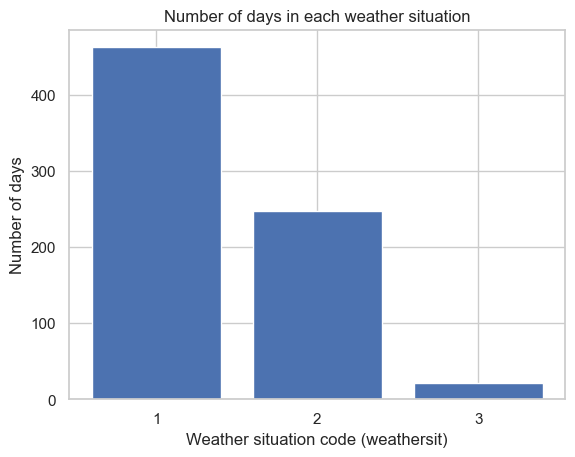

In [ ]:
counts = df["weathersit"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Weather situation code (weathersit)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each weather situation")
plt.show()

## 4 (devam). Tek bir kategorinin sayıları: mevsim (`season`)

Aynı yöntemi bu kez `season` için uygularız: her kodun kaç günde göründüğü (frekans), oranı ve yüzdesi, ardından bar grafiği. Mevsim kodu 1'den 4'e sıralıdır ve döngüseldir (4'ten sonra yeniden 1 gelir); "ortalama mevsim kodu" bir anlam taşımaz. Frekans gün sayısıdır, kiralama sayısı değil.

**Etiket uyarısı.** Veri setinin iki kaynağı kodların anlamını farklı veriyor: UCI sayfasında 1 kış, 2 ilkbahar, 3 yaz, 4 sonbahar; `Readme.txt` dosyasında ise 1 ilkbahar, 2 yaz, 3 sonbahar, 4 kış yazıyor. İkisi birden doğru olamaz. Bu yüzden bu bölümde kodlara isim vermiyoruz, ham kodlarla (1, 2, 3, 4) çalışıyoruz. Doğru etiket, tarih sütunu (`dteday`) dönüştürüldükten sonra kodların hangi tarihlere denk geldiği kontrol edilerek ve kaynak belirtilerek seçilecek.

Çubuk grafiğinde kodların doğal sırası (1, 2, 3, 4) korunur. Hocanın örneğinde adlar sırasızdı ve çubuklar büyüklüğe göre sıralanıyordu; burada sıra bilgisi anlamlı olduğu için sıralamıyoruz.

In [ ]:
print(df["season"].value_counts(dropna=False).sort_index())
known = df["season"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

season
1    181
2    184
3    188
4    178
Name: count, dtype: int64


,f,p,percent
season,,,
1,181,0.247606,24.8
2,184,0.251710,25.2
3,188,0.257182,25.7
4,178,0.243502,24.4


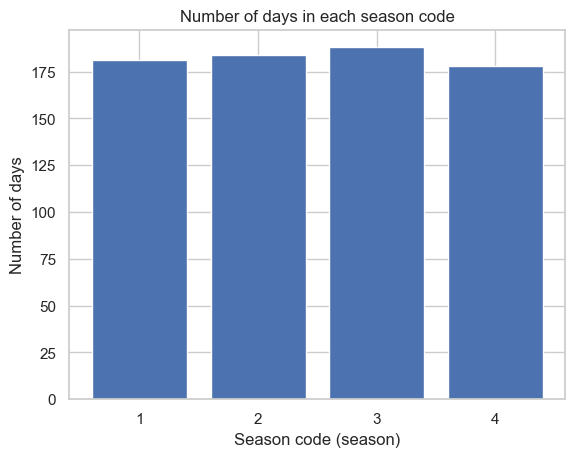

In [ ]:
counts = df["season"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Season code (season)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each season code")
plt.show()

## 4 (devam). Tek bir kategorinin sayıları: çalışma günü (`workingday`)

`workingday` ikili bir koddur: veri dokümantasyonuna göre gün hafta sonu ya da resmi tatil değilse 1, aksi hâlde 0. Yani 0 grubu tek tür gün değil, hafta sonları ile tatillerin karışımıdır. İkili bir kodun ortalamasını yorumlamayız; bunun yerine her kodun frekansına (kaç gün) ve oranına bakarız. Frekans gün sayısıdır, kiralama sayısı değil.

Aynı kalıp uygulanır: frekans, oran (`p`), yüzde, ardından bar grafiği. Kodların doğal sırası 0, 1 olarak korunur. Kodlar ham hâliyle gösterilir, etiket eklenmez.

In [ ]:
print(df["workingday"].value_counts(dropna=False).sort_index())
known = df["workingday"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

workingday
0    231
1    500
Name: count, dtype: int64


,f,p,percent
workingday,,,
0,231,0.316005,31.6
1,500,0.683995,68.4


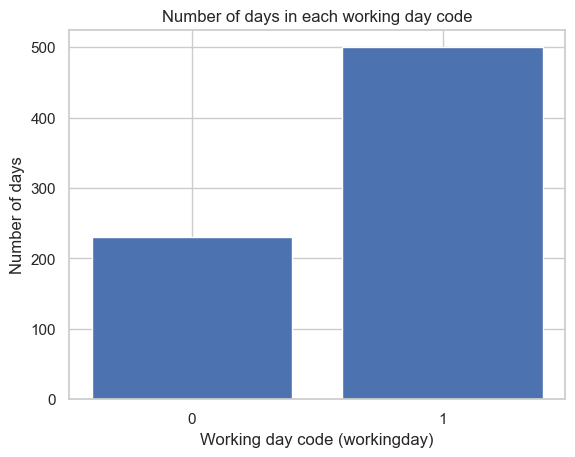

In [ ]:
counts = df["workingday"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Working day code (workingday)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each working day code")
plt.show()

## 4 (devam). Tek bir kategorinin sayıları: haftanın günü (`weekday`)

`weekday`, haftanın gününü 0'dan 6'ya kadar kodlar. Veri dokümantasyonu yalnızca "haftanın günü" diyor, hangi kodun hangi güne karşılık geldiğini yazmıyor. Bunu tarih sütunu (`dteday`) dönüştürüldükten sonra tarihlerle karşılaştırarak doğrulayacağız. O zamana kadar ham kodlarla (0–6) çalışıyoruz ve "0 kodu", "1 kodu" gibi konuşuyoruz. Kodlar sıralı ve döngüseldir (6'dan sonra yeniden 0 gelir), "ortalama gün kodu" bir anlam taşımaz.

Aynı kalıp uygulanır: frekans, oran (`p`), yüzde, ardından bar grafiği. Frekans gün sayısıdır, kiralama sayısı değil. Tablo ardışık günlerden oluşuyorsa her haftada her koddan bir gün bulunacağı için frekansların birbirine çok yakın olması beklenir. Kodların doğal sırası (0, 1, …, 6) korunur ve kodlar ham hâliyle gösterilir.

In [ ]:
print(df["weekday"].value_counts(dropna=False).sort_index())
known = df["weekday"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

weekday
0    105
1    105
2    104
3    104
4    104
5    104
6    105
Name: count, dtype: int64


,f,p,percent
weekday,,,
0,105,0.143639,14.4
1,105,0.143639,14.4
2,104,0.142271,14.2
3,104,0.142271,14.2
4,104,0.142271,14.2
5,104,0.142271,14.2
6,105,0.143639,14.4


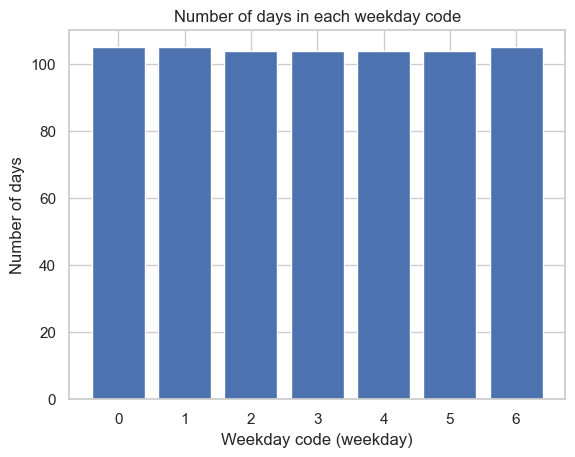

In [ ]:
counts = df["weekday"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Weekday code (weekday)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each weekday code")
plt.show()

## 4 (devam). Tek bir kategorinin sayıları: ay (`mnth`)

`mnth`, ayı 1'den 12'ye kodlar. Kodlar sıralı ve döngüseldir (12'den sonra yeniden 1 gelir); "ortalama ay kodu" bir anlam taşımaz. Frekans gün sayısıdır, kiralama sayısı değil. Kodun takvimdeki ay numarasına karşılık geldiğini tarih sütunu (`dteday`) dönüştürüldükten sonra doğrulayacağız.

Önceki değişkenlerden önemli bir fark: aylar eşit uzunlukta değildir. Tablo 2011 ve 2012 yıllarını tam olarak kapsıyorsa 31 günlük bir ay iki yılda 62 gün, 30 günlük bir ay 60 gün içerir. Şubat ise 2011'de 28, 2012'de (artık yıl) 29 gün olduğundan 57 gün içerir. Bu yüzden frekansların eşit olması beklenmez; farklar ayların takvim uzunluğundan gelir ve veri hatası değildir.

Aynı kalıp uygulanır: frekans, oran (`p`), yüzde, ardından bar grafiği. Kodların doğal sırası (1, 2, …, 12) korunur ve kodlar ham hâliyle gösterilir.

In [ ]:
print(df["mnth"].value_counts(dropna=False).sort_index())
known = df["mnth"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

mnth
1     62
2     57
3     62
4     60
5     62
6     60
7     62
8     62
9     60
10    62
11    60
12    62
Name: count, dtype: int64


,f,p,percent
mnth,,,
1,62,0.084815,8.5
2,57,0.077975,7.8
3,62,0.084815,8.5
4,60,0.082079,8.2
5,62,0.084815,8.5
6,60,0.082079,8.2
7,62,0.084815,8.5
8,62,0.084815,8.5
9,60,0.082079,8.2


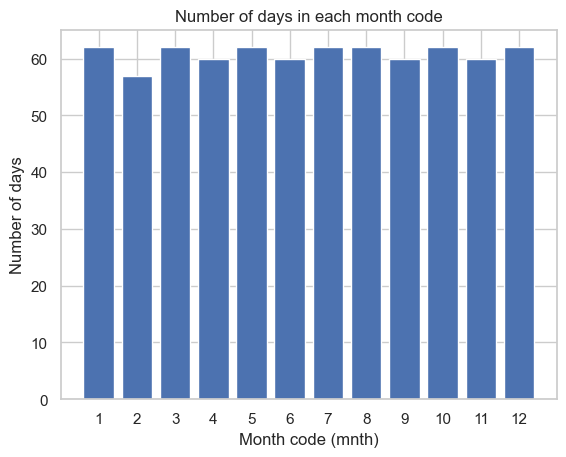

In [ ]:
counts = df["mnth"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Month code (mnth)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each month code")
plt.show()

## 4 (devam). Tek bir kategorinin sayıları: tatil (`holiday`)

`holiday` ikili bir koddur: veri dokümantasyonuna göre günün tatil olup olmadığını gösterir ve bir tatil takviminden alınmıştır. 1 tatil günü, 0 tatil olmayan gündür. İkili bir kodun ortalamasını yorumlamayız; her kodun frekansına (kaç gün) ve oranına bakarız. Frekans gün sayısıdır, kiralama sayısı değil.

`holiday`, `workingday` ile aynı şey değildir. `workingday = 0` hem hafta sonlarını hem de tatilleri içerir, `holiday = 1` ise yalnızca tatil olarak kodlanan günleri gösterir; bir günün hafta sonuna denk gelmesi onu kendiliğinden `holiday = 1` yapmaz. İki sütun birbirinin yerine kullanılmaz.

Tatiller takvimde az sayıda gün tutar, bu yüzden iki grubun belirgin biçimde dengesiz olması beklenir. Aynı kalıp uygulanır: frekans, oran (`p`), yüzde, ardından bar grafiği. Kodların doğal sırası (0, 1) korunur ve kodlar ham hâliyle gösterilir.

In [ ]:
print(df["holiday"].value_counts(dropna=False).sort_index())
known = df["holiday"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

holiday
0    710
1     21
Name: count, dtype: int64


,f,p,percent
holiday,,,
0,710,0.971272,97.1
1,21,0.028728,2.9


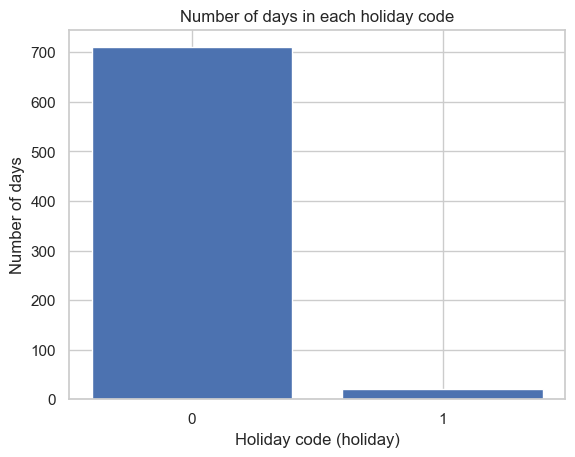

In [ ]:
counts = df["holiday"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Holiday code (holiday)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each holiday code")
plt.show()

## 4 (devam). Tek bir kategorinin sayıları: yıl (`yr`)

`yr` ikili bir koddur: veri dokümantasyonuna göre 0 ilk yılı (2011), 1 ikinci yılı (2012) temsil eder. İkili bir kodun ortalamasını yorumlamayız; her kodun frekansına (kaç gün) ve oranına bakarız. Frekans gün sayısıdır, kiralama sayısı değil. Kodların yıllara karşılık geldiğini tarih sütunu (`dteday`) dönüştürüldükten sonra doğrulayacağız.

Tablo 2011 ve 2012 yıllarını tam olarak kapsıyorsa ilk yıl 365, ikinci yıl 366 gün içermelidir, çünkü 2012 artık yıldır. İki grubun tamamen eşit olması bu yüzden beklenmez; aralarında yalnızca 1 günlük fark beklenir. Bu sonuç yıl kodlarının dönemin yapısıyla uyumunu kontrol etmek için kullanılabilir, ancak tarih sütunu ayrıca doğrulanmadan tek başına kesin kanıt değildir.

Aynı kalıp uygulanır: frekans, oran (`p`), yüzde, ardından bar grafiği. Kodların doğal sırası (0, 1) korunur ve kodlar ham hâliyle gösterilir.

In [ ]:
print(df["yr"].value_counts(dropna=False).sort_index())
known = df["yr"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

yr
0    365
1    366
Name: count, dtype: int64


,f,p,percent
yr,,,
0,365,0.499316,49.9
1,366,0.500684,50.1


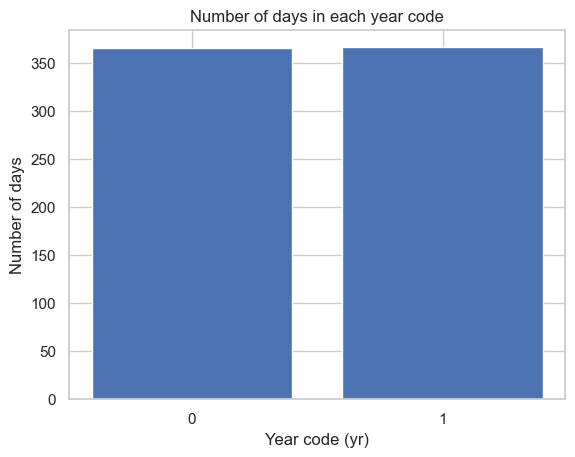

In [ ]:
counts = df["yr"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Year code (yr)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each year code")
plt.show()

## 5. Tarih ve kod doğrulaması

Sayısal analize geçmeden önce, daha önce "ham kodlarla çalışıyoruz" diyerek açık bıraktığımız kontrolleri kapatırız. Bu bölüm yeni bir analiz değil, veri bütünlüğü ve kod doğrulamasıdır: `dteday` metin olarak okunduğu için önce tarihe çevirip tarihlerin kendisine, sonra bu tarihlere dayanarak `yr`, `mnth`, `weekday` ve `season` kodlarına bakarız. Dönüşüm yalnızca geçici bir seride (`dates`) yapılır; `df` değiştirilmez ve yeni sütun eklenmez.

Kontroller ve nedenleri:

- **Dönüşüm ve temel tarih kontrolleri:** Tarih metni gerçekten tarih olarak okunabiliyor mu (`NaT` yoksa evet)? İlk ve son tarih ne, tarihler sıralı mı, tekrar eden tarih var mı?
- **Ardışıklık:** Komşu tarihler arasındaki fark hep 1 gün mü? Fark 1'den büyükse gün atlanmış, 1'den küçükse sıra bozulmuş demektir. Frekans tabloları bunu tek başına kanıtlayamıyordu.
- **`yr` ve `mnth`:** Dokümantasyona göre `yr` 0 = 2011, 1 = 2012; `mnth` takvim ayıdır. Bunu tarihlerin gerçek yılı ve ayıyla karşılaştırırız.
- **`weekday`:** Dokümantasyon hangi kodun hangi güne denk geldiğini yazmıyor. Eşleşmeyi varsaymadan, kod ile gün adını çapraz tabloda yan yana koyup veriden okuruz.
- **`season`:** Etiketler konusunda UCI sayfası ve Readme çelişiyor. Burada yalnızca kodların hangi aylarda göründüğünü gösteririz; etiketi bu tablodan atamayız.

In [ ]:
dates = pd.to_datetime(df["dteday"], errors="coerce")
print("failed conversions (NaT):", dates.isna().sum())
print("first date:", dates.min().date(), "| last date:", dates.max().date())
print("in chronological order:", dates.is_monotonic_increasing)
print("repeated dates:", dates.duplicated().sum())

failed conversions (NaT): 0
first date: 2011-01-01 | last date: 2012-12-31
in chronological order: True
repeated dates: 0


In [ ]:
gaps = dates.diff().dt.days
print(gaps.value_counts(dropna=False))
print("transitions that are not 1 day:", (gaps.dropna() != 1).sum())
print("days from first to last date (inclusive):", (dates.max() - dates.min()).days + 1, "| rows:", len(df))

dteday
1.0    730
NaN      1
Name: count, dtype: int64
transitions that are not 1 day: 0
days from first to last date (inclusive): 731 | rows: 731


In [ ]:
print("rows where yr does not match the real year:", (df["yr"] != dates.dt.year - 2011).sum())
pd.crosstab(df["yr"], dates.dt.year)

rows where yr does not match the real year: 0


dteday,2011,2012
yr,,
0,365,0
1,0,366


In [ ]:
print("rows where mnth does not match the real month:", (df["mnth"] != dates.dt.month).sum())

rows where mnth does not match the real month: 0


In [ ]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
table = pd.crosstab(df["weekday"], dates.dt.day_name())[day_order]
print(table.idxmax(axis=1))
print("non-zero cells:", int((table > 0).sum().sum()))
table

weekday
0       Sunday
1       Monday
2      Tuesday
3    Wednesday
4     Thursday
5       Friday
6     Saturday
dtype: object
non-zero cells: 7


dteday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
weekday,,,,,,,
0,0,0,0,0,0,0,105
1,105,0,0,0,0,0,0
2,0,104,0,0,0,0,0
3,0,0,104,0,0,0,0
4,0,0,0,104,0,0,0
5,0,0,0,0,104,0,0
6,0,0,0,0,0,105,0


In [ ]:
pd.crosstab(df["mnth"], df["season"])

season,1,2,3,4
mnth,,,,
1,62,0,0,0
2,57,0,0,0
3,40,22,0,0
4,0,60,0,0
5,0,62,0,0
6,0,40,20,0
7,0,0,62,0
8,0,0,62,0
9,0,0,44,16


## 6. Sayısal değişkenler: temel özet ve merkez

Kategorik değişkenleri sayarak inceledik; sayısal değişkenlerde soru "ne kadar" olur. `describe` olağan sayıları tek tabloda toplar: kaç gözlem olduğu (`count`), ortalama (`mean`), standart sapma (`std`), en küçük ve en büyük değer (`min`, `max`) ve çeyrekler (`25%`, `50%`, `75%`). Ortalama her değeri kullandığı için uç bir değer onu çekebilir; medyan (`50%`) sıralı değerlerin ortasıdır ve yerinde kalır. Bu yüzden ikisini yan yana koyarız: aralarındaki fark dağılımın simetrik olup olmadığına dair yalnızca ilk bir izlenim verir, kesin bir sonuç değil.

Beş değişken: `cnt` bir günün toplam kiralama sayısıdır. `temp`, `atemp`, `hum` ve `windspeed` 0–1 arasına ölçeklenmiş (normalize) değerlerdir; gerçek birimleri (°C, %, rüzgâr birimi) değildir ve bu bölümde yalnızca bu ölçekte yorumlanır. `casual` ve `registered`, `cnt`'nin parçaları olduğu için bu özetin dışında bırakıldı.

`count`, eksik olmayan gözlem sayısıdır. Bölüm 3'te iki hücreyi eksik yaptığımız için `hum` ve `atemp` için 730, diğerleri için 731 beklenir. pandas eksik hücreleri bu hesaplarda otomatik dışarıda bırakır; hiçbir değer doldurulmaz ve `df` değişmez.

In [4]:
numeric = ["cnt", "temp", "atemp", "hum", "windspeed"]
df[numeric].describe().round(3)

,cnt,temp,atemp,hum,windspeed
count,731.000,731.000,730.000,730.000,731.000
mean,4504.349,0.495,0.475,0.629,0.190
std,1937.211,0.183,0.163,0.141,0.077
min,22.000,0.059,0.079,0.188,0.022
25%,3152.000,0.337,0.338,0.521,0.135
50%,4548.000,0.498,0.487,0.627,0.181
75%,5956.000,0.655,0.609,0.730,0.233
max,8714.000,0.862,0.841,0.972,0.507


In [ ]:
pd.DataFrame({
    "mean": df[numeric].mean(),
    "median": df[numeric].median(),
    "mean - median": df[numeric].mean() - df[numeric].median(),
}).round(3)

,mean,median,mean - median
cnt,4504.349,4548.000,-43.651
temp,0.495,0.498,-0.003
atemp,0.475,0.487,-0.013
hum,0.629,0.627,0.002
windspeed,0.190,0.181,0.010


## 7. Yayılım

Merkez, değerlerin nerede toplandığını söyler; yayılım ise onların merkez etrafında ne kadar dağıldığını. Varyans, ortalamadan uzaklıkların karelerinin ortalamasıdır, bu yüzden değişkenin biriminin karesiyle ölçülür. Standart sapma varyansın kareköküdür ve değişkenin kendi ölçeğine geri döner. pandas örneklem varyansını (n − 1'e bölerek) hesaplar ve eksik hücreleri dışarıda bırakır.

Varyasyon katsayısı (CV), standart sapmanın ortalamaya oranıdır ve yüzde olarak da yazılır. Birimsizdir, bu yüzden farklı ölçeklerdeki değişkenlerin yayılımını karşılaştırmayı mümkün kılar. Ama bu yalnızca sıfırın "hiç yok" anlamına geldiği (oran) ölçeklerde geçerlidir: `cnt`, `hum` ve `windspeed` için sıfır böyledir. `temp` ve `atemp` ise normalize edilirken bir alt sınır çıkarılarak ölçeklendi; normalize sıfır, sıcaklığın fiziksel sıfırı değil o alt sınırdır. Ortalama keyfi bir noktadan ölçüldüğü için bu iki değişkende CV, değişkenler arası kıyas için anlamlı değildir. CV'yi hesaplarız ama bu amaçla yorumlamayız.

Ham standart sapmalar da farklı ölçeklerde olduğundan doğrudan karşılaştırılmaz: `cnt`'nin standart sapması kiralama sayısı biriminde, diğerlerininki 0–1 normalize ölçeğindedir. Eksik değer doldurulmaz; `hum` ve `atemp` 730, diğerleri 731 gözleme dayanır.

In [ ]:
pd.DataFrame({
    "variance": df[numeric].var(),
    "std": df[numeric].std(),
}).round(5)

,variance,std
cnt,3.752788e+06,1937.21145
temp,3.351000e-02,0.18305
atemp,2.652000e-02,0.16285
hum,1.977000e-02,0.14061
windspeed,6.010000e-03,0.07750


In [ ]:
ratio = df[numeric].std() / df[numeric].mean()
pd.DataFrame({
    "CV": ratio,
    "CV (%)": 100 * ratio,
}).round(3)

,CV,CV (%)
cnt,0.430,43.008
temp,0.370,36.951
atemp,0.343,34.307
hum,0.224,22.364
windspeed,0.407,40.684


## 8. Çeyrekler ve Tukey çitleri

Q1, medyan ve Q3 sıralı değerleri dört eşit parçaya böler. IQR, Q3 eksi Q1'dir: orta yarının genişliği. Tukey çitleri Q1'in 1,5 IQR altında ve Q3'ün 1,5 IQR üstünde yer alır. Bir çitin dışında kalan değer **potansiyel aykırı değer**dir: kontrol edilecek bir adaydır, otomatik hata değildir. pandas çeyrekleri aradeğerleme (interpolasyon) ile hesaplar, bu yüzden elle yapılan hesaptan küçük farklar çıkabilir.

Çitler her değişken için kendi ölçeğinde ve iki yılı (2011–2012) birleştiren dağılıma göre hesaplanır. Bu yüzden bir gün, tek başına olağandışı olduğu için değil, yılların ya da mevsimlerin karışımı yüzünden de çit dışında kalabilir. `hum` ve `atemp` için 730, diğerleri için 731 gözlem kullanılır; eksik hücreler doldurulmaz ve hesaba girmez.

Bölüm 3'te eksik yapılan iki hücre bu bölümle karıştırılmamalıdır. Onlar, komşu günlerle ve aynı satırdaki diğer değerlerle tutarsız oldukları için işaretlenmişti. Tukey çiti ise yalnızca dağılımın yapısına bakan bir kuraldır. Bu bölümde hiçbir satır silinmez, hiçbir değer değiştirilmez.

In [ ]:
q1 = df[numeric].quantile(0.25)
q3 = df[numeric].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "lower fence": lower,
    "upper fence": upper,
}).round(3)

,Q1,Q3,IQR,lower fence,upper fence
cnt,3152.000,5956.000,2804.000,-1054.000,10162.000
temp,0.337,0.655,0.318,-0.140,1.133
atemp,0.338,0.609,0.271,-0.068,1.015
hum,0.521,0.730,0.210,0.206,1.045
windspeed,0.135,0.233,0.098,-0.012,0.381


In [ ]:
below = (df[numeric] < lower).sum()
above = (df[numeric] > upper).sum()
pd.DataFrame({
    "below lower fence": below,
    "above upper fence": above,
    "total": below + above,
})

,below lower fence,above upper fence,total
cnt,0,0,0
temp,0,0,0
atemp,0,0,0
hum,1,0,1
windspeed,0,13,13


In [ ]:
col = "hum"
outside = (df[col] < lower[col]) | (df[col] > upper[col])
print(col, "outside fences:", outside.sum())
df.loc[outside, ["dteday", "weathersit", col]]

hum outside fences: 1


,dteday,weathersit,hum
49,2011-02-19,1,0.187917


In [ ]:
col = "windspeed"
outside = (df[col] < lower[col]) | (df[col] > upper[col])
print(col, "outside fences:", outside.sum())
df.loc[outside, ["dteday", "weathersit", col]]

windspeed outside fences: 13


,dteday,weathersit,windspeed
44,2011-02-14,1,0.417908
49,2011-02-19,1,0.507463
93,2011-04-04,1,0.385571
94,2011-04-05,2,0.388067
292,2011-10-20,1,0.422275
382,2012-01-18,1,0.415429
407,2012-02-12,1,0.409212
420,2012-02-25,1,0.421642
432,2012-03-08,1,0.441563
433,2012-03-09,2,0.414800


## 9. Z-skorları

Z-skoru, bir değerin ortalamadan kaç standart sapma uzakta olduğunu söyler: (x − ortalama) / standart sapma. `|z| > 2` başka bir uç gözlem kuralıdır; evrensel bir hata eşiği değil, dersteki inceleme kuralıdır. Bu kural ortalamayı ve standart sapmayı kullanır, bu yüzden uç değerler ve uzun bir kuyruk bu iki ölçüyü çekerek eşikleri kaydırabilir. Tukey çitleri çeyreklere dayanır ve bu etkiden daha az etkilenir. İki kural farklı günleri işaretleyebilir. Hangi kuralı kullandığımızı söyleriz ve işaretlenen günlere "potansiyel uç gözlem" deriz, "hata" değil.

Hesapta pandas'ın örneklem standart sapması (n − 1) kullanılır, önceki bölümlerle tutarlıdır. `hum` ve `atemp`'teki birer eksik hücre doldurulmaz; bu hücrelerin z-skoru da eksik kalır. Z-skorları geçici bir `z` tablosunda tutulur, `df`'e yeni sütun eklenmez. Bölüm 3'te eksik yapılan iki hücre bu analizle karıştırılmamalıdır: onlar veri tutarsızlığı nedeniyle işaretlenmişti, z-skoru ise dağılıma dayanan bir kuraldır. Hiçbir satır silinmez, hiçbir değer değiştirilmez.

In [ ]:
z = (df[numeric] - df[numeric].mean()) / df[numeric].std()
z.describe().round(2)

,cnt,temp,atemp,hum,windspeed
count,731.00,731.00,730.00,730.00,731.00
mean,-0.00,-0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00
min,-2.31,-2.38,-2.43,-3.14,-2.17
25%,-0.70,-0.86,-0.84,-0.77,-0.72
50%,0.02,0.02,0.08,-0.01,-0.12
75%,0.75,0.87,0.82,0.72,0.55
max,2.17,2.00,2.25,2.44,4.09


In [ ]:
z_below = (z < -2).sum()
z_above = (z > 2).sum()
pd.DataFrame({
    "z < -2": z_below,
    "z > 2": z_above,
    "total |z| > 2": z_below + z_above,
})

,z < -2,z > 2,total |z| > 2
cnt,7,3,10
temp,5,1,6
atemp,8,4,12
hum,12,15,27
windspeed,1,34,35


In [ ]:
col = "windspeed"
flagged = z[col].abs() > 2
print(col, "|z| > 2:", flagged.sum())
pd.DataFrame({
    "dteday": df["dteday"],
    col: df[col],
    "z": z[col].round(2),
}).loc[flagged].sort_values("z", key=abs, ascending=False).head(15)

windspeed |z| > 2: 35


,dteday,windspeed,z
49,2011-02-19,0.507463,4.09
432,2012-03-08,0.441563,3.24
292,2011-10-20,0.422275,2.99
420,2012-02-25,0.421642,2.98
44,2011-02-14,0.417908,2.93
382,2012-01-18,0.415429,2.90
433,2012-03-09,0.414800,2.89
407,2012-02-12,0.409212,2.82
721,2012-12-22,0.407346,2.80
666,2012-10-28,0.398008,2.68


In [ ]:
pd.DataFrame({
    "mean - 2 std": df[numeric].mean() - 2 * df[numeric].std(),
    "mean + 2 std": df[numeric].mean() + 2 * df[numeric].std(),
}).round(3)

,mean - 2 std,mean + 2 std
cnt,629.926,8378.772
temp,0.129,0.861
atemp,0.149,0.800
hum,0.348,0.910
windspeed,0.035,0.345


## 10. Dağılımın şekli: çarpıklık ve basıklık

`skew`, derste kullanılan düzeltilmiş çarpıklık ölçüsüdür. Sıfırın üstü: sağ kuyruk daha uzun ve ortalama genellikle medyanın üstünde. Sıfırın altı: sol kuyruk daha uzun. `kurt`, pandas'ta fazla basıklıktır (excess kurtosis): normal bir eğriye yakın kuyruklarda değer yaklaşık 0'dır. Birkaç yüz satırla basıklık hâlâ kabadır; histogramın yanında okunur, yerine geçmez. Bölüm 6'daki ortalama–medyan izlenimlerini burada sınarız.

`hum` ve `atemp` için eksik hücreler doldurulmaz, pandas bunları otomatik dışarıda bırakır. `df` değişmez.

In [5]:
pd.DataFrame({
    "skew": df[numeric].skew(),
    "kurtosis": df[numeric].kurt(),
}).round(3)

,skew,kurtosis
cnt,-0.047,-0.812
temp,-0.055,-1.119
atemp,-0.133,-0.981
hum,0.031,-0.456
windspeed,0.677,0.411


## 11. Histogram

Histogram, değerleri aralıklara (bin) böler ve her aralıktaki gün sayısını çubukla gösterir; gruplanmış frekans tablosunun resmidir. Bin sayısı görünen şekli etkiler. İlk hücrede dersteki Sturges kuralı kullanılır (k = ⌈1 + log₂ n⌉, bu veri için 11): sade ve kaba bir görüntü verir. İkinci hücrede 25 bin kullanılır: bir tepe yalnızca birinde görünüyorsa yazılı özete almayız.

Her değişken kendi ölçeğinde ayrı bir histogramda gösterilir. `temp`, `atemp`, `hum` ve `windspeed` normalize ölçeklidir. Eksik hücreler dışarıda bırakılır, doldurulmaz; `df` değişmez.

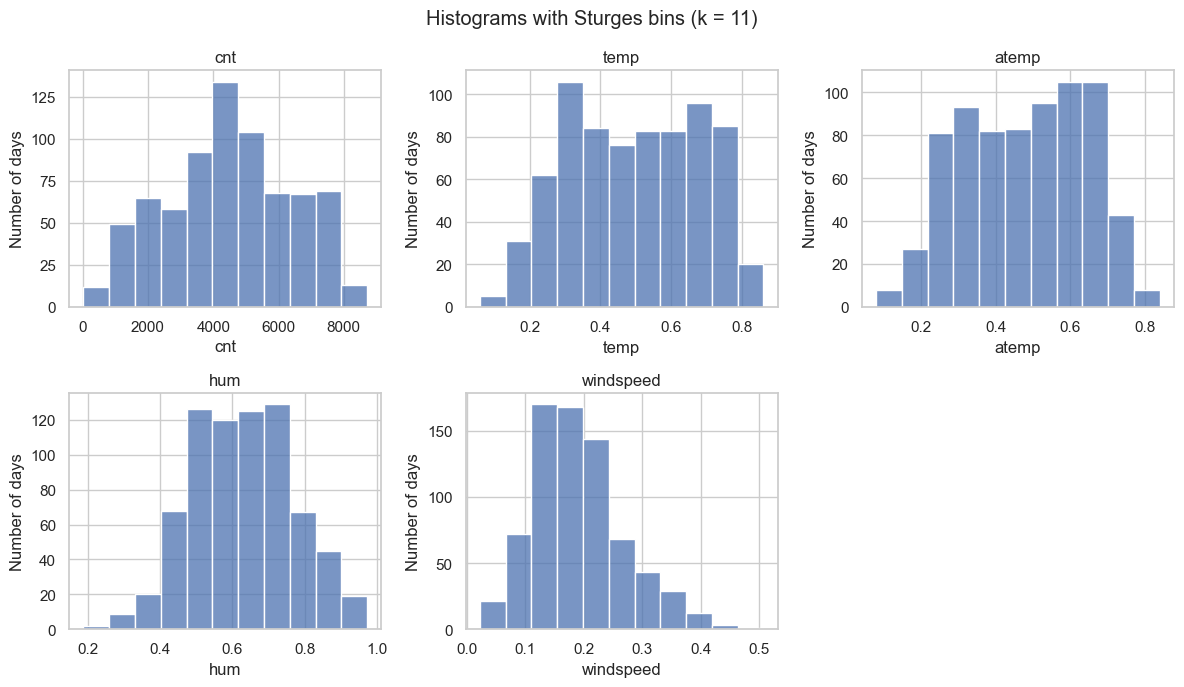

In [6]:
k = math.ceil(1 + math.log2(len(df)))
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.flat, numeric):
    sns.histplot(df[col].dropna(), bins=k, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of days")
axes.flat[-1].set_visible(False)
fig.suptitle(f"Histograms with Sturges bins (k = {k})")
fig.tight_layout()
plt.show()

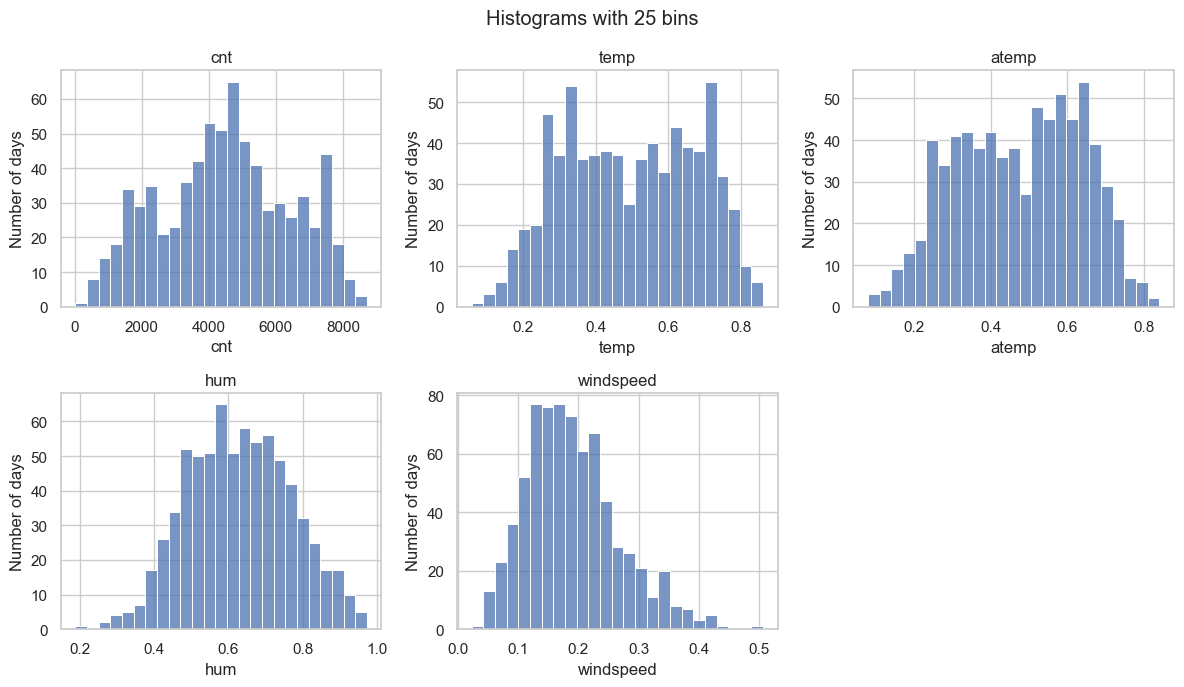

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.flat, numeric):
    sns.histplot(df[col].dropna(), bins=25, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of days")
axes.flat[-1].set_visible(False)
fig.suptitle("Histograms with 25 bins")
fig.tight_layout()
plt.show()

## 12. Yoğunluk eğrisi (KDE)

Yoğunluk eğrisi (KDE), histogramın yumuşatılmış görünümüdür: her gözleme küçük bir tümsek koyar ve tümsekleri toplar. Tümseğin genişliği (bandwidth), bin genişliği gibi bir seçimdir; fazla ya da az yumuşatma görünen tepeleri değiştirebilir. Eğrinin altındaki alan 1'dir, bu yüzden histogramın yoğunluk (density) hâliyle üst üste çizilir ve dikey eksen gün sayısı değil yoğunluktur. KDE'den kesin bir normal dağılım ya da çok tepeli yapı sonucu çıkarmayız.

Her değişken kendi ölçeğinde ayrı bir panelde gösterilir. Eksik hücreler dışarıda bırakılır, doldurulmaz; `df` değişmez.

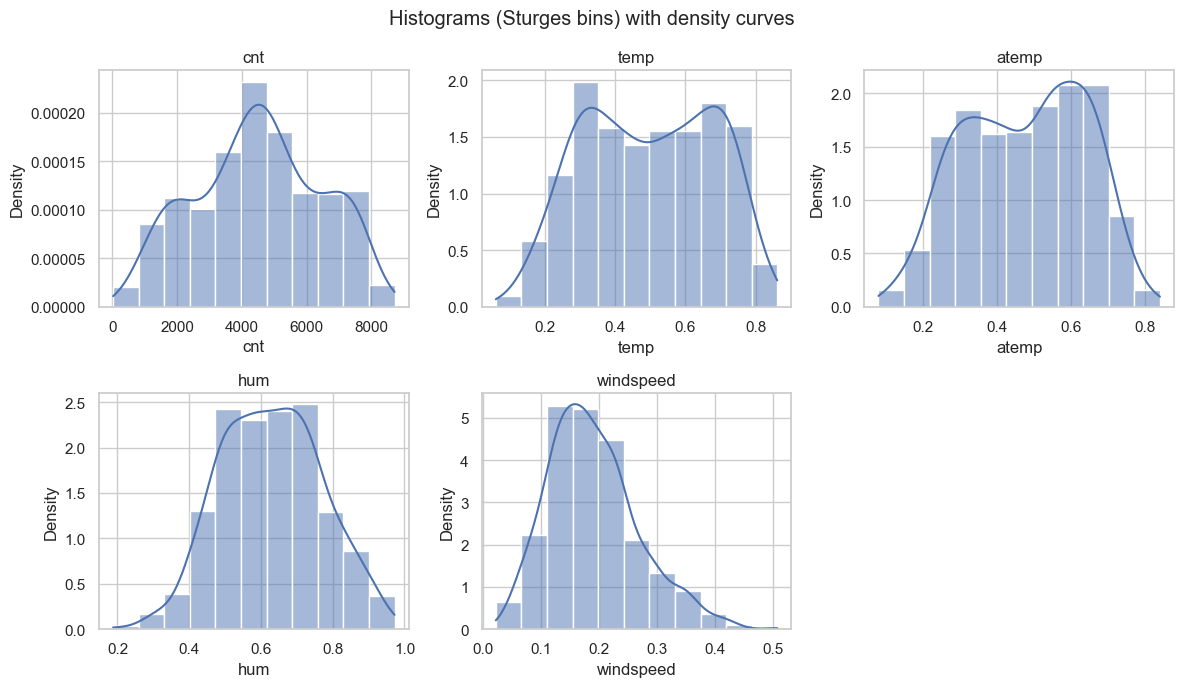

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.flat, numeric):
    sns.histplot(df[col].dropna(), bins=k, stat="density", kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
axes.flat[-1].set_visible(False)
fig.suptitle("Histograms (Sturges bins) with density curves")
fig.tight_layout()
plt.show()

## 13. Boxplot

Kutu Q1'den Q3'e uzanır, içindeki çizgi medyandır. Bıyıklar (whisker), Tukey çitlerinin içinde kalan son gözlemde biter; çitlerin ötesindeki gözlemler tek tek nokta olarak çizilir. Yani boxplot, Q1, medyan, Q3 ve Tukey adaylarını tek resimde gösterir. Bölüm 8'deki sayımlarla aynı olmalıdır: `cnt`, `temp` ve `atemp`'te nokta yok, `hum`'da 1 düşük, `windspeed`'de 13 yüksek aday. Çitler değişkenin olası aralığının dışında kaldığında bıyık veri sınırında biter.

Çizilen bir nokta potansiyel aykırı değerdir, hata değildir; resim gözlemin nedenini söylemez. Her değişken kendi ölçeğinde ayrı bir panelde gösterilir. Eksik hücreler dışarıda bırakılır, doldurulmaz; `df` değişmez.

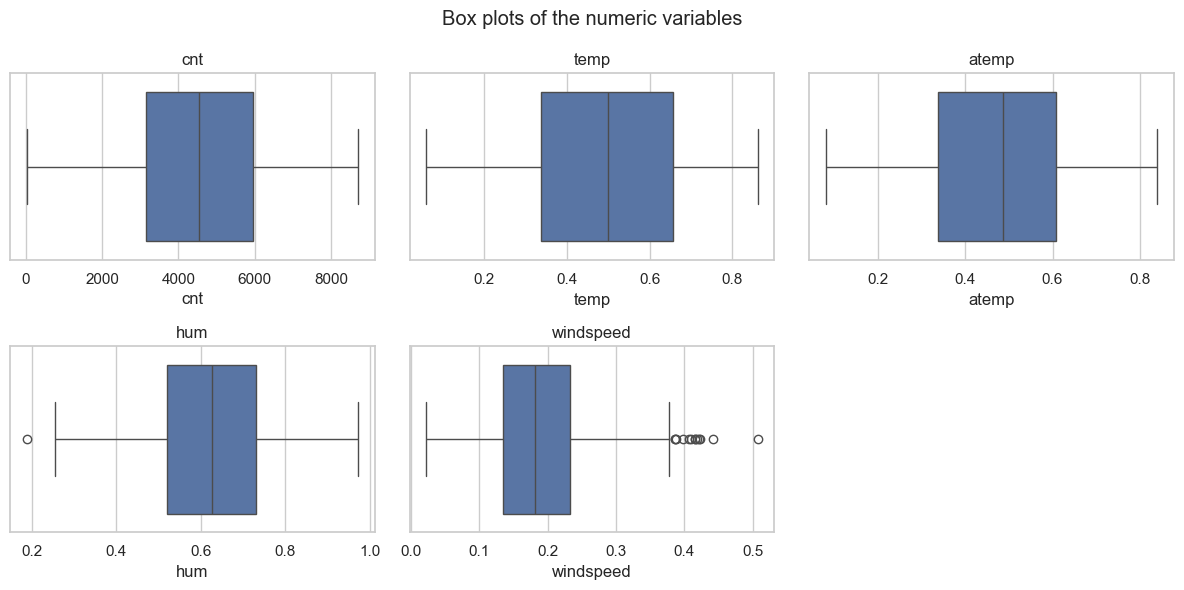

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, numeric):
    sns.boxplot(x=df[col].dropna(), ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
axes.flat[-1].set_visible(False)
fig.suptitle("Box plots of the numeric variables")
fig.tight_layout()
plt.show()

## 14. Violin plot

Violin, boxplot'a yoğunluk eğrisinin aynadaki görüntüsünü ekler. Kutunun gizlediği iki tepe gibi ayrıntılar görünür kalır. Dış çizgi KDE'ye dayandığı için bandwidth seçimine duyarlıdır, bu yüzden çok tepeli bir yapıyı tek başına kanıt saymayız. Violin'in içindeki küçük kutuda kalın çizgi Q1'den Q3'e uzanır, beyaz nokta medyandır.

Seaborn'un varsayılanında violin, veri aralığının ötesine uzanır. Burada `cut=0` ile veri aralığında kesiyoruz, böylece örneğin negatif kiralama sayısı gibi veride olmayan uçlar görünmez. Her değişken kendi ölçeğinde ayrı bir panelde gösterilir. Eksik hücreler dışarıda bırakılır, doldurulmaz; `df` değişmez.

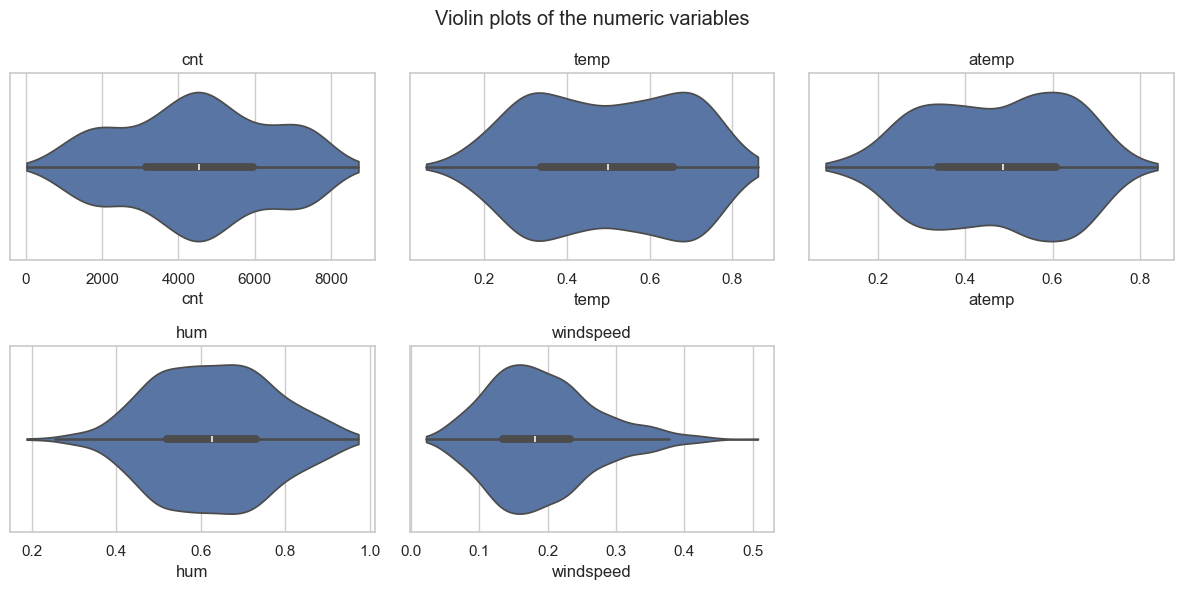

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, numeric):
    sns.violinplot(x=df[col].dropna(), cut=0, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
axes.flat[-1].set_visible(False)
fig.suptitle("Violin plots of the numeric variables")
fig.tight_layout()
plt.show()

## 15. Stem-and-leaf

Stem-and-leaf her değeri bir kök (üst basamaklar) ve bir yaprağa (son basamak) böler. Satır uzunluğu histogramdaki çubuk gibi şekli gösterir, ama her yaprak gerçek bir değeri (yaprak basamağına kadar) korur: değerleri hâlâ gösteren bir histogramdır. Dersteki kural: kısa listede kullan; birkaç düzine satırdan sonra okunaksız olur ve araç histogramdır.

731 günün tamamı yüzlerce yaprak demektir, bu yüzden dersteki gibi rastgele 24 günlük bir örnek gösteririz (`random_state=2`). 24 gün tablonun yalnızca yaklaşık %3'üdür; dağılımın şekli için histogram ve yoğunluk eğrisi asıl araçtır.

Yaprak çözünürlüğü değişkene göre değişir. `cnt` için kök binler, yaprak yüzlerdir (yüzlüğe kesilmiş). Normalize değişkenlerde kök onda bir, yaprak yüzde birdir (iki ondalığa yuvarlanmış). Eksik hücreler dışarıda bırakılır, doldurulmaz; `df` değişmez.

In [6]:
sample = sorted(int(value) for value in (df["cnt"] // 100).sample(24, random_state=2))
buckets = {}
for value in sample:
    stem, leaf = divmod(value, 10)
    buckets.setdefault(stem, []).append(leaf)
for stem in range(min(buckets), max(buckets) + 1):
    leaves = " ".join(str(leaf) for leaf in buckets.get(stem, []))
    print(f"{stem} | {leaves}")
print("Key: 4 | 5 = 4500-4599 rentals")

0 | 6 9
1 | 2 4 7 9
2 | 
3 | 1 3 7 8 8 8
4 | 5 5 5 6 9
5 | 3 8
6 | 2
7 | 2
8 | 0 2 5
Key: 4 | 5 = 4500-4599 rentals


In [7]:
col = "windspeed"
scaled = (df[col].dropna() * 100).round()
sample = sorted(int(value) for value in scaled.sample(24, random_state=2))
buckets = {}
for value in sample:
    stem, leaf = divmod(value, 10)
    buckets.setdefault(stem, []).append(leaf)
for stem in range(min(buckets), max(buckets) + 1):
    leaves = " ".join(str(leaf) for leaf in buckets.get(stem, []))
    print(f"{stem} | {leaves}")
print("Key: 1 | 7 = 0.17")

0 | 5 6 8 9
1 | 0 2 3 6 7 7 7 7 7 9 9
2 | 2 2 3 5 5 5 6 7
3 | 7
Key: 1 | 7 = 0.17


## 16. İki kategori: `holiday` × `workingday`

Bir çapraz tablo (contingency table), iki değişkenin her değer çiftinden kaç gün olduğunu sayar; `margins` her değişkenin tek başına toplamlarını ekler. Satır yüzdeleri şu soruyu cevaplar: tatil olan (ya da olmayan) günlerin kaçı çalışma günü? Ki-kare testi, iki değişken ilişkisiz olsaydı hücrelerde bulunacak beklenen sayılarla gözlenen sayılar arasındaki uzaklığı toplar. Cramér's V bunu 0–1 arasına ölçekler: yaklaşık 0,1 zayıf, 0,3 orta, 0,5 güçlü bir ilişkidir. Küçük bir p-değeri, farkın bu örnek büyüklüğü için büyük olduğunu söyler, birinin diğerine neden olduğunu değil. Her beklenen sayı en az 5 olmalıdır.

Bu iki değişken tanımsal olarak ilişkilidir: `workingday = 0` hafta sonu ya da tatil demektir, yani `holiday = 1` olan bir gün `workingday = 1` olamaz. Bu yüzden anlamlı bir ki-kare yeni bir keşif değil, tanımın veride yansımasıdır ve nedensellik olarak yorumlanmaz. 2 × 2 tablolarda `scipy` varsayılan olarak Yates süreklilik düzeltmesi uygular; dersteki kalıp korunur. `df` değişmez.

In [8]:
pd.crosstab(df["holiday"], df["workingday"], margins=True)

workingday,0,1,All
holiday,,,
0,210,500,710
1,21,0,21
All,231,500,731


In [9]:
pd.crosstab(df["holiday"], df["workingday"], normalize="index").round(3)

workingday,0,1
holiday,,
0,0.296,0.704
1,1.000,0.000


In [10]:
counts = pd.crosstab(df["holiday"], df["workingday"])
chi2, p_value, dof, expected = stats.chi2_contingency(counts)
print("chi-square", round(chi2, 2))
print("df", dof)
print("p", "< 0.0001" if p_value < 0.0001 else round(p_value, 4))
print("smallest expected count", round(expected.min(), 1))
pd.DataFrame(expected, index=counts.index, columns=counts.columns).round(1)

chi-square 43.6
df 1
p < 0.0001
smallest expected count 6.6


workingday,0,1
holiday,,
0,224.4,485.6
1,6.6,14.4


In [11]:
n = counts.to_numpy().sum()
v = (chi2 / (n * (min(counts.shape) - 1))) ** 0.5
print("Cramers V", round(v, 3))

Cramers V 0.244


## 17. `cnt` yıllara göre

Bu bölümde kategorilere göre günlük kiralama sayısına (`cnt`) bakmaya başlıyoruz; ilk değişken `yr` (0 = 2011, 1 = 2012, Bölüm 5'te tarihlerle doğrulandı). Bölüm 6 ve 7'deki merkez ve yayılım özetleri iki yılı birleştiriyordu; burada iki yılı ayrı ayrı görürüz.

Önce `yr`'ye göre bölüp her grupta gün sayısını, ortalamayı, medyanı ve standart sapmayı hesaplarız. İki grup aynı ortalamaya sahip olup yayılımda farklı olabilir, bu yüzden ortalama tek başına karşılaştırma değildir. Gruplar 365 ve 366 gündür; toplam kiralama yerine gün başına ortalama ve medyan karşılaştırılır. Grup ortalamalarını birleştirirken her birini gün sayısıyla ağırlıklandırırız.

Sonra iki yılın kutularını aynı ölçekte yan yana koyarız: çizgilere (merkez), kutu uzunluklarına (yayılım) ve örtüşmeye bakılır. Bu bölüm betimleyicidir: istatistiksel anlamlılık testi yapılmaz ve bir fark görülürse nedeni hakkında sonuç çıkarılmaz. `casual` ve `registered` kullanılmaz; `df` değişmez.

In [12]:
summary = df.groupby("yr")["cnt"].agg(["count", "mean", "median", "std"])
weighted = (summary["count"] * summary["mean"]).sum() / summary["count"].sum()
print("weighted mean", round(weighted, 2))
print("unweighted mean of means", round(summary["mean"].mean(), 2))
summary.round(2)

weighted mean 4504.35
unweighted mean of means 4502.85


,count,mean,median,std
yr,,,,
0,365,3405.76,3740.0,1378.75
1,366,5599.93,5927.0,1788.67


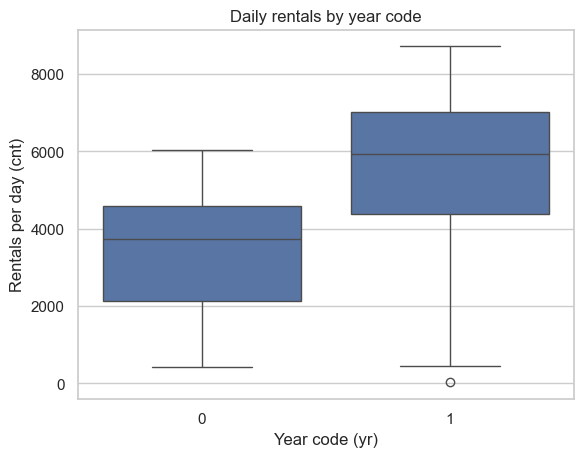

In [13]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="yr", y="cnt", order=[0, 1], ax=ax)
ax.set_xlabel("Year code (yr)")
ax.set_ylabel("Rentals per day (cnt)")
ax.set_title("Daily rentals by year code")
plt.show()

## 18. `cnt` çalışma günü koduna göre

Aynı karşılaştırmayı `workingday` için yaparız. `workingday = 0` yalnızca hafta sonu değildir: Bölüm 16'daki çapraz tabloya göre bu 231 günün 210'u tatil olmayan günler (hafta sonları), 21'i tatil günleridir. `workingday = 1` ise 500 gündür. Bu yüzden 0 grubu "hafta sonu etkisi" diye adlandırılmaz, hafta sonu ve tatil günlerinin karışımı olarak okunur.

Gruplar eşit değildir (231 ve 500 gün), bu yüzden toplam kiralama yerine gün başına ortalama ve medyan karşılaştırılır. Önce `workingday`'e göre bölüp her grupta gün sayısını, ortalamayı, medyanı ve standart sapmayı hesaplarız; grup ortalamalarını birleştirirken her birini gün sayısıyla ağırlıklandırırız, çünkü büyük grubun ortalamasını küçük grupla eşit saymak genel ortalamayı kaydırır. Sonra iki grubun kutularını aynı ölçekte yan yana koyarız: çizgilere (merkez), kutu uzunluklarına (yayılım) ve örtüşmeye bakılır. Küçük grupta çeyrekler daha oynaktır, gün sayısı resmin yanında okunur.

Bu bölüm betimleyicidir: istatistiksel anlamlılık testi yapılmaz ve bir fark görülürse nedeni hakkında sonuç çıkarılmaz. İki yıl birleşik gözlemlerdir; Bölüm 17'deki yıllar arası fark ayrıca akılda tutulur. `casual` ve `registered` kullanılmaz; `df` değişmez.

In [14]:
summary = df.groupby("workingday")["cnt"].agg(["count", "mean", "median", "std"])
weighted = (summary["count"] * summary["mean"]).sum() / summary["count"].sum()
print("weighted mean", round(weighted, 2))
print("unweighted mean of means", round(summary["mean"].mean(), 2))
summary.round(2)

weighted mean 4504.35
unweighted mean of means 4457.49


,count,mean,median,std
workingday,,,,
0,231,4330.17,4459.0,2052.14
1,500,4584.82,4582.0,1878.42


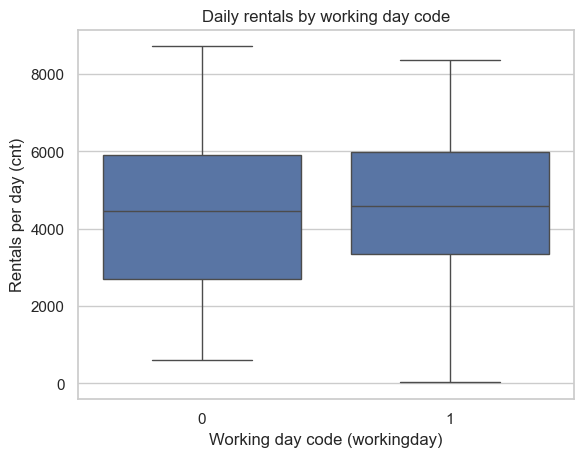

In [15]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="workingday", y="cnt", order=[0, 1], ax=ax)
ax.set_xlabel("Working day code (workingday)")
ax.set_ylabel("Rentals per day (cnt)")
ax.set_title("Daily rentals by working day code")
plt.show()

## 19. `cnt` tatil koduna göre

Aynı karşılaştırmayı `holiday` için yaparız. Gruplar çok dengesizdir: 710 gün tatil değil, yalnızca **21 gün** tatil. Bu yüzden `holiday = 1` grubunun ortalaması, medyanı ve çeyrekleri, bir ya da iki sıra dışı günden kolayca etkilenebilecek kadar kararsızdır; farklar temkinle okunur. `holiday = 0` grubu yalnızca sıradan hafta içi günlerden oluşmaz: Bölüm 16'ya göre 710 günün 500'ü çalışma günü, 210'u hafta sonudur. Tatil günleri ise hafta içine denk gelir (Bölüm 5 ve 16). Bu yüzden karşılaştırma "tatil ile her türlü tatil olmayan gün" arasındadır.

Gruplar eşit olmadığından toplam kiralama yerine gün başına ortalama ve medyan karşılaştırılır. Önce `holiday`'e göre bölüp her grupta gün sayısını, ortalamayı, medyanı ve standart sapmayı hesaplarız; grup ortalamalarını gün sayısıyla ağırlıklandırırız. Sonra iki grubun kutularını aynı ölçekte yan yana koyarız. Küçük grupta kutu kabadır, gün sayısı resmin yanında okunur.

Bu bölüm betimleyicidir: istatistiksel anlamlılık testi yapılmaz ve bir fark görülürse nedeni hakkında sonuç çıkarılmaz. İki yıl birleşik gözlemlerdir; Bölüm 17'deki yıllar arası fark ayrıca akılda tutulur. `casual` ve `registered` kullanılmaz; `df` değişmez.

In [16]:
summary = df.groupby("holiday")["cnt"].agg(["count", "mean", "median", "std"])
weighted = (summary["count"] * summary["mean"]).sum() / summary["count"].sum()
print("weighted mean", round(weighted, 2))
print("unweighted mean of means", round(summary["mean"].mean(), 2))
summary.round(2)

weighted mean 4504.35
unweighted mean of means 4131.05


,count,mean,median,std
holiday,,,,
0,710,4527.1,4558.0,1929.01
1,21,3735.0,3351.0,2103.35


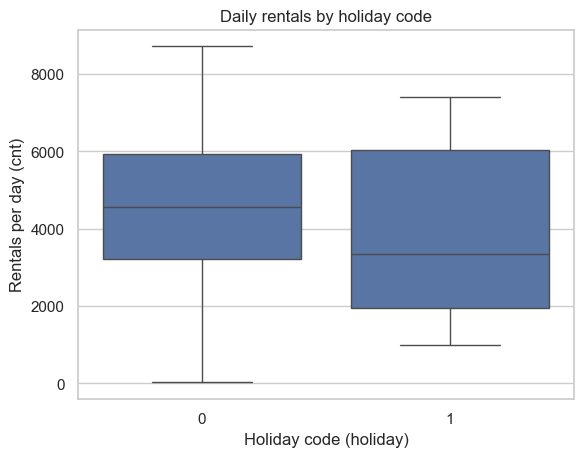

In [17]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="holiday", y="cnt", order=[0, 1], ax=ax)
ax.set_xlabel("Holiday code (holiday)")
ax.set_ylabel("Rentals per day (cnt)")
ax.set_title("Daily rentals by holiday code")
plt.show()

## 20. `cnt` hava durumu koduna göre

Aynı karşılaştırmayı `weathersit` için yaparız. Dokümantasyona göre 1 açık ya da az bulutlu, 2 sisli/puslu ve bulutlu, 3 hafif kar ya da hafif yağmur günlerini kodlar; günlük veride 4 kodu yoktur (Bölüm 2 ve 4), bu yüzden olmayan bir grup oluşturulmaz. Gruplar yaklaşık 463, 247 ve 21 gündür (Bölüm 4). Kod 3 çok küçüktür: ortalama, medyan ve çeyrekleri bir ya da iki sıra dışı günden kolayca etkilenebilir, bu yüzden temkinle okunur.

Kodların doğal bir sırası vardır ama aralarındaki fark eşit kabul edilmez; bu yüzden kod ortalaması hesaplanmaz ve kutular 1, 2, 3 sırasıyla dizilir. Gruplar eşit olmadığından toplam kiralama yerine gün başına ortalama ve medyan karşılaştırılır. Önce `weathersit`'e göre bölüp her grupta gün sayısını, ortalamayı, medyanı ve standart sapmayı hesaplarız; grup ortalamalarını gün sayısıyla ağırlıklandırırız. Sonra üç grubun kutularını aynı ölçekte yan yana koyarız.

Bu bölüm betimleyicidir: yalnızca hava durumu grupları arasında gözlenen günlük kiralama farkları incelenir; istatistiksel anlamlılık testi yapılmaz ve nedensellik iddia edilmez. İki yıl birleşik gözlemlerdir; yıllar arası düzey farkı (Bölüm 17) ve hava durumunun mevsimlere dağılımı karıştırıcı olabilir. `casual` ve `registered` kullanılmaz; `df` değişmez.

In [18]:
summary = df.groupby("weathersit")["cnt"].agg(["count", "mean", "median", "std"])
weighted = (summary["count"] * summary["mean"]).sum() / summary["count"].sum()
print("weighted mean", round(weighted, 2))
print("unweighted mean of means", round(summary["mean"].mean(), 2))
summary.round(2)

weighted mean 4504.35
unweighted mean of means 3571.98


,count,mean,median,std
weathersit,,,,
1,463,4876.79,4844.0,1879.48
2,247,4035.86,4040.0,1809.11
3,21,1803.29,1817.0,1240.28


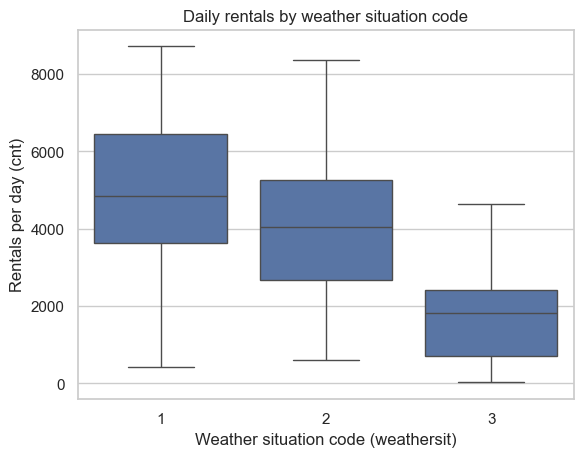

In [19]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="weathersit", y="cnt", order=[1, 2, 3], ax=ax)
ax.set_xlabel("Weather situation code (weathersit)")
ax.set_ylabel("Rentals per day (cnt)")
ax.set_title("Daily rentals by weather situation code")
plt.show()

## 21. `cnt` mevsim koduna göre

Aynı karşılaştırmayı `season` için yaparız. Mevsim isimleri kullanılmaz: UCI sayfası ile `Readme.txt` kodların anlamında çeliştiği için Bölüm 5'te ham kodlarla (1, 2, 3, 4) çalışmaya karar verdik. Kodlar döngüseldir ve takvim aylarıyla örtüşmez (Bölüm 5), bu yüzden "kod arttıkça" gibi doğrusal bir okuma yapılmaz; her kod ayrı bir grup olarak okunur. Gruplar yaklaşık dengelidir (181, 184, 188 ve 178 gün, Bölüm 4).

Gruplar yaklaşık eşit olsa da toplam kiralama yerine gün başına ortalama ve medyan karşılaştırılır. Önce `season`'a göre bölüp her grupta gün sayısını, ortalamayı, medyanı ve standart sapmayı hesaplarız; grup ortalamalarını gün sayısıyla ağırlıklandırırız. Gruplar neredeyse eşit olduğundan ağırlıklı ve ağırlıksız ortalamanın birbirine yakın çıkması beklenir, yine de ikisini göstereriz. Sonra dört grubun kutularını aynı ölçekte yan yana koyarız.

Bu bölüm betimleyicidir: istatistiksel anlamlılık testi yapılmaz ve gözlenen bir fark için neden iddia edilmez. Her kod iki yılın günlerini de içerir; Bölüm 17'deki yıllar arası düzey farkı grupların içindeki yayılımı artırmış olabilir. `casual` ve `registered` kullanılmaz; `df` değişmez.

In [20]:
summary = df.groupby("season")["cnt"].agg(["count", "mean", "median", "std"])
weighted = (summary["count"] * summary["mean"]).sum() / summary["count"].sum()
print("weighted mean", round(weighted, 2))
print("unweighted mean of means", round(summary["mean"].mean(), 2))
summary.round(2)

weighted mean 4504.35
unweighted mean of means 4492.23


,count,mean,median,std
season,,,,
1,181,2604.13,2209.0,1399.94
2,184,4992.33,4941.5,1695.98
3,188,5644.30,5353.5,1459.80
4,178,4728.16,4634.5,1699.62


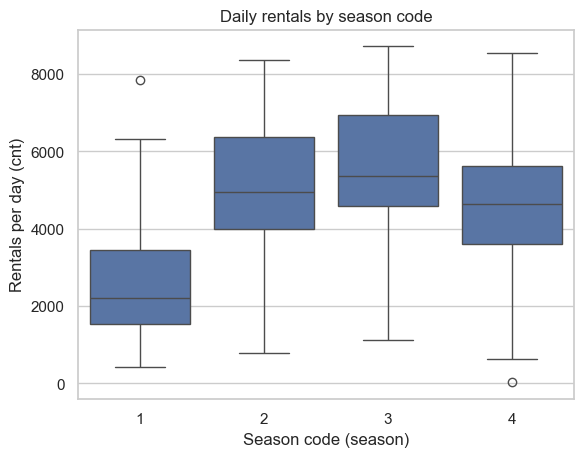

In [21]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="season", y="cnt", order=[1, 2, 3, 4], ax=ax)
ax.set_xlabel("Season code (season)")
ax.set_ylabel("Rentals per day (cnt)")
ax.set_title("Daily rentals by season code")
plt.show()

## 22. `cnt` ay koduna göre

Aynı karşılaştırmayı `mnth` için yaparız. Bölüm 5'te `mnth` kodlarının takvim ay numarasıyla birebir eşleştiği doğrulandı; yine de kodlar ham hâliyle (1–12) kullanılır. Ay kodları döngüseldir (12'den sonra yeniden 1 gelir), bu yüzden "ay numarası arttıkça" gibi doğrusal bir okuma yapılmaz; her kod ayrı bir grup olarak okunur. Gruplar yaklaşık dengelidir (57–62 gün, Bölüm 4). Veri iki yılı tam kapsadığı için her ay iki yıldan eşit sayıda gün içerir (Şubat'ta 28 ve 29).

Ayların uzunlukları biraz farklı olduğundan toplam kiralama yerine gün başına ortalama ve medyan karşılaştırılır. Önce `mnth`'a göre bölüp her grupta gün sayısını, ortalamayı, medyanı ve standart sapmayı hesaplarız; grup ortalamalarını gün sayısıyla ağırlıklandırırız. Gruplar yaklaşık eşit olduğundan ağırlıklı ve ağırlıksız ortalamanın birbirine yakın çıkması beklenir, yine de ikisini göstereriz. Sonra on iki grubun kutularını aynı ölçekte yan yana koyarız.

Bu bölüm betimleyicidir: istatistiksel anlamlılık testi yapılmaz ve gözlenen bir fark için neden iddia edilmez. Her ay iki yılın günlerini de içerir; Bölüm 17'deki yıllar arası düzey farkı grupların içindeki yayılımı artırmış olabilir. `casual` ve `registered` kullanılmaz; `df` değişmez.

In [4]:
summary = df.groupby("mnth")["cnt"].agg(["count", "mean", "median", "std"])
weighted = (summary["count"] * summary["mean"]).sum() / summary["count"].sum()
print("weighted mean", round(weighted, 2))
print("unweighted mean of means", round(summary["mean"].mean(), 2))
summary.round(2)

weighted mean 4504.35
unweighted mean of means 4497.98


,count,mean,median,std
mnth,,,,
1,62,2176.34,1939.0,1161.67
2,57,2655.30,2402.0,1145.31
3,62,3692.26,3216.5,1899.30
4,60,4484.90,4293.5,1776.16
5,62,5349.77,4890.5,1298.71
6,60,5772.37,5308.5,1240.40
7,62,5563.68,5446.5,1273.75
8,62,5664.42,5229.5,1494.52
9,60,5766.52,5384.0,1810.13


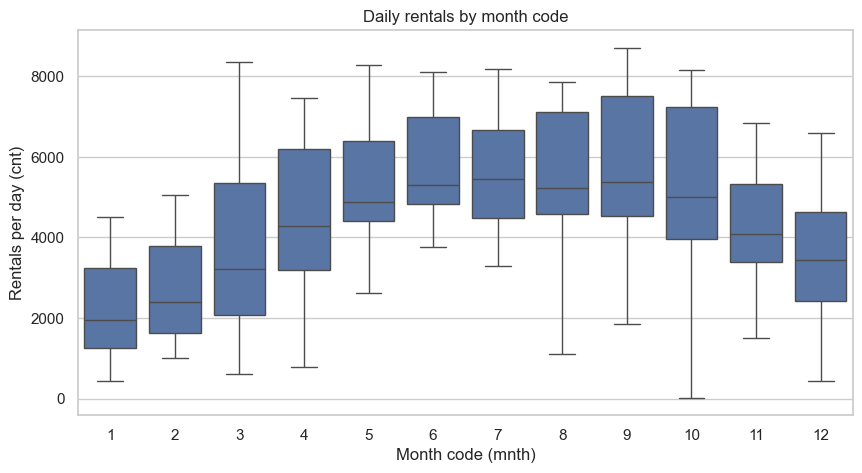

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x="mnth", y="cnt", order=list(range(1, 13)), ax=ax)
ax.set_xlabel("Month code (mnth)")
ax.set_ylabel("Rentals per day (cnt)")
ax.set_title("Daily rentals by month code")
plt.show()

## 23. `cnt` haftanın gününe göre

Aynı karşılaştırmayı `weekday` için yaparız. Bölüm 5'te tarihlerle doğrulandığı gibi 0 Pazar, 1 Pazartesi, 2 Salı, 3 Çarşamba, 4 Perşembe, 5 Cuma ve 6 Cumartesi'dir; yine de grafikte ham kodlar (0–6) kalır. Kodlar döngüseldir (6'dan sonra yeniden 0 gelir), bu yüzden "kod arttıkça" gibi doğrusal bir okuma yapılmaz; her kod ayrı bir grup olarak okunur. Gruplar çok dengelidir (104–105 gün, Bölüm 4) ve her kod iki yıldan gözlem içerir.

`weekday`, `workingday` ve `holiday` ile kavramsal olarak ilişkilidir: 0 ve 6 kodları hafta sonu günleridir, 1–5 kodları hafta içi günleridir ve hafta içi günlerin bir kısmı tatile denk gelir (Bölüm 5 ve 16). Bu bölümde bu ilişkiyi ayrıca incelemeyiz, yalnızca akılda tutarız.

Toplam kiralama yerine gün başına ortalama ve medyan karşılaştırılır. Önce `weekday`'e göre bölüp her grupta gün sayısını, ortalamayı, medyanı ve standart sapmayı hesaplarız; grup ortalamalarını gün sayısıyla ağırlıklandırırız. Gruplar neredeyse eşit olduğundan ağırlıklı ve ağırlıksız ortalamanın çok yakın çıkması beklenir, yine de ikisini göstereriz. Sonra yedi grubun kutularını aynı ölçekte yan yana koyarız.

Bu bölüm betimleyicidir: istatistiksel anlamlılık testi yapılmaz ve gözlenen bir fark için neden iddia edilmez. İki yıl birleşik gözlemlerdir; Bölüm 17'deki yıllar arası düzey farkı grupların içindeki yayılımı artırmış olabilir. `casual` ve `registered` kullanılmaz; `df` değişmez.

In [6]:
summary = df.groupby("weekday")["cnt"].agg(["count", "mean", "median", "std"])
weighted = (summary["count"] * summary["mean"]).sum() / summary["count"].sum()
print("weighted mean", round(weighted, 2))
print("unweighted mean of means", round(summary["mean"].mean(), 2))
summary.round(2)

weighted mean 4504.35
unweighted mean of means 4504.89


,count,mean,median,std
weekday,,,,
0,105,4228.83,4334.0,1872.50
1,105,4338.12,4359.0,1793.07
2,104,4510.66,4576.5,1826.91
3,104,4548.54,4642.5,2038.10
4,104,4667.26,4721.0,1939.43
5,104,4690.29,4601.5,1874.62
6,105,4550.54,4521.0,2196.69


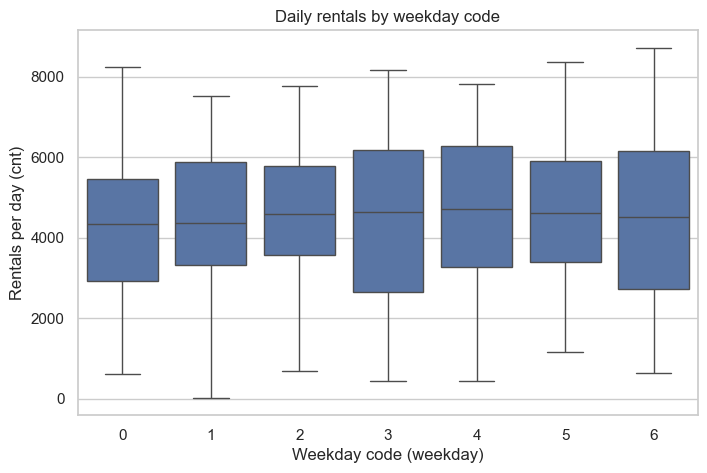

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="weekday", y="cnt", order=list(range(7)), ax=ax)
ax.set_xlabel("Weekday code (weekday)")
ax.set_ylabel("Rentals per day (cnt)")
ax.set_title("Daily rentals by weekday code")
plt.show()

## 24. Sayısal değişkenler arası ilişki: kovaryans, Pearson ve Spearman

Bu bölümde `cnt` ile `temp`, `atemp`, `hum` ve `windspeed` arasındaki ilişkiye bakıyoruz; önce yalnızca sayısal tablolar. Kovaryans, iki sütunun ortalamalarından sapmalarının çarpımının ortalamasıdır. Pozitif işaret sütunların birlikte hareket ettiğini gösterir. Sayı birimleri taşır (kiralama sayısı çarpı normalize birim), bu yüzden büyüklüğü ilişkinin gücü değildir. Korelasyon birimleri ortadan kaldırır.

Pearson r, kovaryansı iki standart sapmaya böler. −1 ile 1 arasındadır ve doğrusal ilişkiyi ölçer; köşegen 1'dir. Dersteki yaklaşık yorum eşikleri: |r| < 0,3 zayıf, 0,3 ile 0,7 arası orta, 0,7 ve üstü güçlü. Bu eşikler yaklaşıktır, kesin sınır değildir. Güçlü bir çift gereksiz tekrar olabilir. Spearman ρ, sıralar üzerinde hesaplanan Pearson'dır: yön olarak sürekli artan ya da azalan (monoton) her ilişkiyi izler ve tek tük uç noktalardan daha az etkilenir. İki sayı birbirine yakınsa bulut doğruya yakındır. İkisinden birini alıntılamadan önce saçılım grafiğine bakılmalıdır, bu bir sonraki adım.

Korelasyon nedensellik değildir. `casual` ve `registered` `cnt`'nin parçaları olduğu için dışarıda bırakılmıştır; `yr`, `mnth`, `season`, `weekday`, `workingday`, `holiday` ve `weathersit` kodlu değişkenler olduğu için bu bölüme girmez. `hum` ve `atemp`'teki birer eksik hücre doldurulmaz; pandas her çift için geçerli gözlemleri kullanır. İki yıl birleşiktir, yıl ve mevsim hem hava değişkenleriyle hem kiralamayla birlikte hareket ediyor olabilir. `df` değişmez.

In [8]:
df[numeric].cov().round(4)

,cnt,temp,atemp,hum,windspeed
cnt,3.752788e+06,222.5147,200.3369,-31.1590,-35.2122
temp,2.225147e+02,0.0335,0.0297,0.0032,-0.0022
atemp,2.003369e+02,0.0297,0.0265,0.0032,-0.0023
hum,-3.115900e+01,0.0032,0.0032,0.0198,-0.0027
windspeed,-3.521220e+01,-0.0022,-0.0023,-0.0027,0.0060


In [9]:
df[numeric].corr().round(3)

,cnt,temp,atemp,hum,windspeed
cnt,1.000,0.627,0.635,-0.115,-0.235
temp,0.627,1.000,0.997,0.125,-0.158
atemp,0.635,0.997,1.000,0.138,-0.183
hum,-0.115,0.125,0.138,1.000,-0.246
windspeed,-0.235,-0.158,-0.183,-0.246,1.000


In [10]:
df[numeric].corr(method="spearman").round(3)

,cnt,temp,atemp,hum,windspeed
cnt,1.000,0.622,0.627,-0.103,-0.217
temp,0.622,1.000,0.998,0.129,-0.147
atemp,0.627,0.998,1.000,0.137,-0.168
hum,-0.103,0.129,0.137,1.000,-0.237
windspeed,-0.217,-0.147,-0.168,-0.237,1.000


## 25. Saçılım grafikleri ve doğrusal çizgi

Bu bölümde `cnt` ile `temp`, `atemp`, `hum` ve `windspeed` arasındaki ilişkiler saçılım grafikleriyle incelenir. Her değişken için `linregress` ile doğrusal çizgi hesaplanır ve `r`, `R²`, eğim ve p-değeri elde edilir.

Pearson korelasyonu ilişkinin gücünü özetlerken saçılım grafiği ilişkinin biçimini gösterir. `R²`, basit doğrusal regresyonda `r²` değeridir ve `cnt` değişkenindeki varyasyonun doğrusal model tarafından açıklanan oranını gösterir.

`hum` ve `atemp` değişkenlerindeki eksik gözlemler ilgili çiftlerde `dropna()` ile dışarıda bırakılır. Korelasyon ve regresyon sonuçları nedensellik olarak yorumlanmaz.

In [10]:
weather = ["temp", "atemp", "hum", "windspeed"]

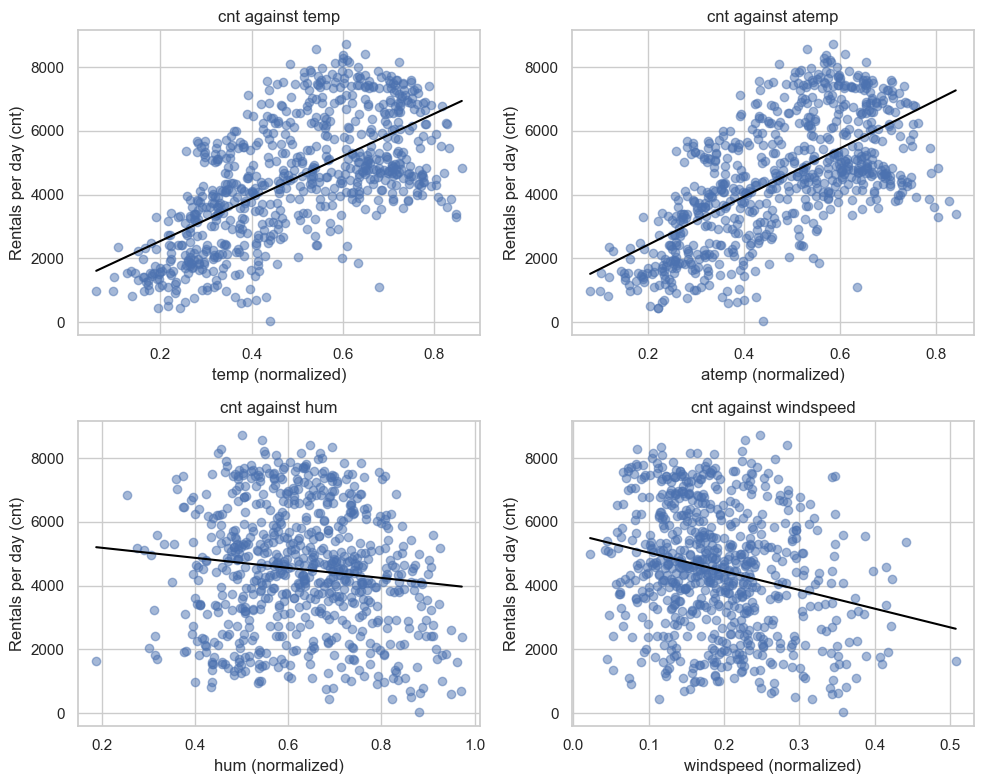

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, col in zip(axes.flat, weather):
    pair = df[[col, "cnt"]].dropna()
    slope, intercept, r, p_value, se = stats.linregress(pair[col], pair["cnt"])
    ax.scatter(pair[col], pair["cnt"], alpha=0.5)
    x = np.linspace(pair[col].min(), pair[col].max(), 50)
    ax.plot(x, intercept + slope * x, color="black")
    ax.set_xlabel(col + " (normalized)")
    ax.set_ylabel("Rentals per day (cnt)")
    ax.set_title("cnt against " + col)
fig.tight_layout()
plt.show()

In [12]:
rows = []
for col in weather:
    pair = df[[col, "cnt"]].dropna()
    result = stats.linregress(pair[col], pair["cnt"])
    rows.append({"variable": col, "n": len(pair), "slope": result.slope,
                 "intercept": result.intercept, "R2": result.rvalue ** 2,
                 "r": result.rvalue, "p_value": result.pvalue, "stderr": result.stderr})
pd.DataFrame(rows).set_index("variable").round({"slope": 2, "intercept": 1, "R2": 3, "r": 3, "stderr": 2})

,n,slope,intercept,R2,r,p_value,stderr
variable,,,,,,,
temp,731,6640.71,1214.6,0.394,0.627,2.810622e-81,305.19
atemp,730,7554.50,914.8,0.404,0.635,8.295253e-84,340.24
hum,730,-1575.89,5500.5,0.013,-0.115,1.922752e-03,506.18
windspeed,731,-5862.91,5621.2,0.055,-0.235,1.359959e-10,899.99


## 26. Üçüncü bir sütun balon büyüklüğü olarak

Bubble plot, x ve y konumunu korur ve üçüncü bir sayıyı alanla kodlar; burada her nokta bir gündür. Konum `temp` ve `cnt`'yi, balon büyüklüğü `windspeed`'i gösterir. Alan ölçeklenir, yarıçap değil, yoksa büyük bir değer devasa görünür; seaborn'un `sizes` ayarı alanı ölçekler. Büyüklük yalnızca kaba bir büyüklüğü okumak içindir; `windspeed` kesin okunacaksa renk ya da ayrı bir grafik kullanılır. 731 nokta olduğundan balon aralığı hocanın örneğinden küçük tutuldu. Bu grafik keşifsel ve betimleyicidir: balon büyüklüğünden kesin bir ilişki ya da neden çıkarılmaz. `df` değişmez.

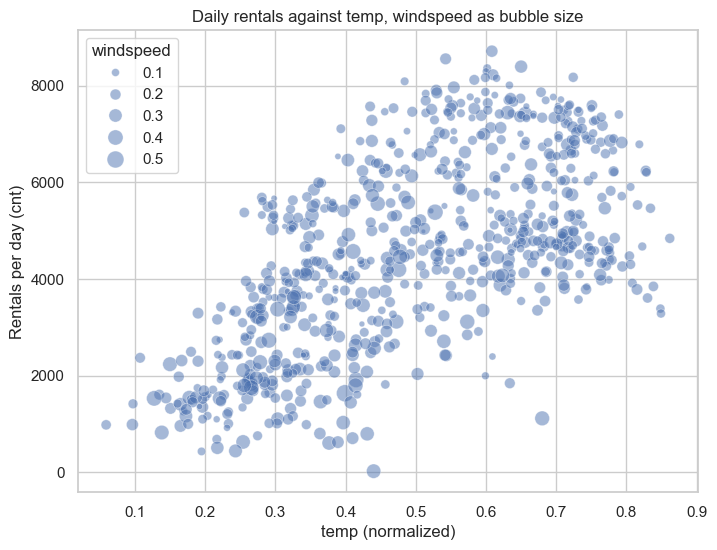

In [13]:
plot_df = df.dropna(subset=["temp", "cnt", "windspeed"])
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=plot_df,
    x="temp",
    y="cnt",
    size="windspeed",
    sizes=(10, 150),
    alpha=0.5,
    ax=ax,
)
ax.set_xlabel("temp (normalized)")
ax.set_ylabel("Rentals per day (cnt)")
ax.set_title("Daily rentals against temp, windspeed as bubble size")
plt.show()

## 27. Aynı grafik panellerde: `temp` × `cnt` yıllara göre

Bir facet, tek bir grafiği her grup için tekrarlar ve eksenleri aynı tutar; göz, üst üste binmiş renkleri ayırmak yerine panelleri karşılaştırabilir. Ortak eksen işin özüdür: her panel kendi ölçeğini seçseydi aynı yükseklik aynı anlama gelmezdi. Burada `temp` × `cnt` saçılımı `yr` koduna göre iki panelde gösterilir (0 = 2011, 1 = 2012, Bölüm 5'te tarihlerle doğrulandı); kodlar ham kalır. Her panelde bir nokta bir günü gösterir ve siyah çizgi o yılın en küçük kareler doğrusudur. Çizgi betimleyicidir, güven bandı çizilmez.

Amaç, Bölüm 25'te görülen farklı yoğunlukların yıl düzeyi farkıyla (Bölüm 17) ilişkili olup olmadığını görsel olarak incelemektir. Görsel bir ilişki nedensellik değildir; bir yılın düzeyinin daha yüksek olması sıcaklığın etkisinin arttığı anlamına gelmez. `casual` ve `registered` kullanılmaz; `df` değişmez.

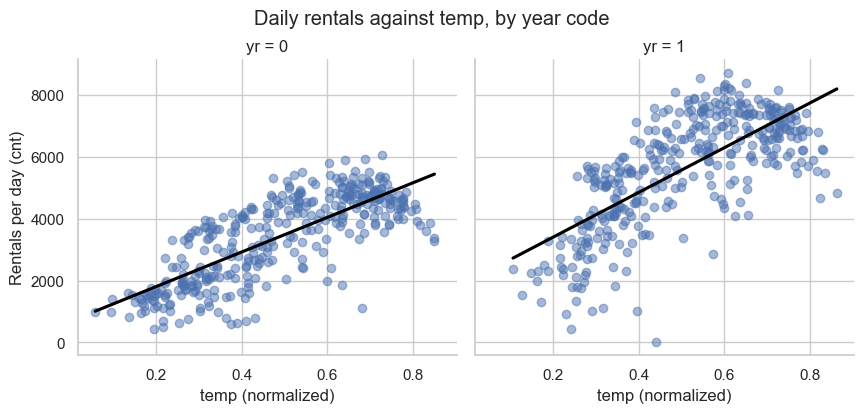

In [14]:
g = sns.lmplot(
    data=df,
    x="temp",
    y="cnt",
    col="yr",
    col_order=[0, 1],
    ci=None,
    height=4,
    aspect=1.1,
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "black"},
)
g.set_axis_labels("temp (normalized)", "Rentals per day (cnt)")
g.figure.suptitle("Daily rentals against temp, by year code", y=1.03)
plt.show()

## 28. Korelasyon heatmap'i

Bölüm 24'teki Pearson korelasyon matrisini renklendiririz. Zıt renkli bir palet sıfırı nötr renge koyar ve ölçek −1 ile 1 arasında sabittir, böylece aynı renk her zaman aynı anlama gelir; sayılar hücrelerde kalır. Bu grafik Bölüm 24'ün görsel özetidir, yeni bir istatistiksel sonuç değildir. Güçlü görünen her çift için saçılım grafiği (Bölüm 25) gerekir: renk bir taramadır, kanıt değildir. `hum` ve `atemp`'teki birer eksik hücre doldurulmaz; pandas her çift için geçerli gözlemleri kullanır. `casual`, `registered` ve kodlu değişkenler matriste yoktur; `df` değişmez.

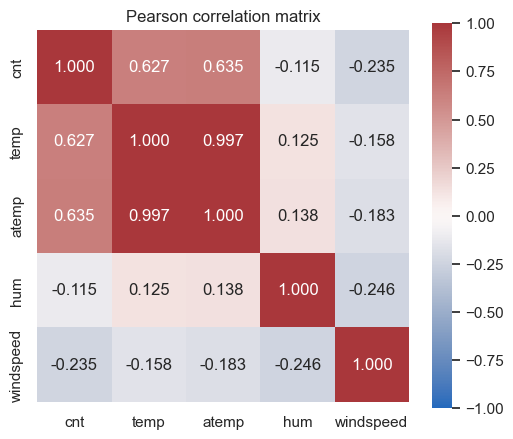

In [15]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    df[numeric].corr(),
    annot=True,
    fmt=".3f",
    vmin=-1,
    vmax=1,
    center=0,
    cmap="vlag",
    square=True,
    ax=ax,
)
ax.set_title("Pearson correlation matrix")
plt.show()